In [ ]:
# -*- coding: utf-8 -*-
"""
Geographical distribution of bee gene expression studies
Step 1: Upload Excel file
Step 2: Read and clean Country column
Step 3: Generate choropleth map with blue fill and numerical labels
"""

# Install required packages if needed
try:
    import plotly.express as px
    import plotly.graph_objects as go
except ImportError:
    !pip install -q plotly kaleido
    import plotly.express as px
    import plotly.graph_objects as go

try:
    import kaleido
except ImportError:
    !pip install -q kaleido

import pandas as pd
import re
from collections import Counter
import os
from google.colab import files

print("="*60)
print("🗺️  Geographical distribution of bee gene expression studies")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your Excel file (e.g., Reviewd_papers_...xlsx)")
uploaded = files.upload()

if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

# Get the uploaded filename
FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

# Try to find the correct sheet
target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: EXTRACT AND COUNT COUNTRIES (preserving multi‑word names)
# ============================================================================

# Aliases to map to Plotly‑recognised country names
COUNTRY_ALIASES = {
    'US': 'United States',
    'USA': 'United States',
    'U.S.': 'United States',
    'UK': 'United Kingdom',
    'GB': 'United Kingdom',
    'Korea': 'Republic of Korea',
    'South Korea': 'Republic of Korea',
    'Czechia': 'Czech Republic',
    'Czech': 'Czech Republic',
}

def extract_countries(entry):
    """
    Split on ; , / & (but NOT on spaces) to keep multi‑word country names.
    Remove 'collaboration' and other noise, then map aliases.
    """
    if pd.isna(entry):
        return []
    text = str(entry)
    # Replace ' and ' with '&' to treat as delimiter
    text = text.replace(' and ', ' & ')
    # Split only on explicit delimiters
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        # Remove noise words (but keep country names)
        p = re.sub(r'\b(collaboration|the|of|with)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p.lower() == 'not reported':
            continue
        if p and len(p) > 1:
            p = COUNTRY_ALIASES.get(p, p)  # apply alias if needed
            cleaned.append(p)
    return cleaned

# Process all entries
all_countries = []
for entry in df['Country']:
    all_countries.extend(extract_countries(entry))

country_counts = Counter(all_countries)
# Remove any leftover "Not reported"
country_counts.pop('Not reported', None)

# Convert to DataFrame
country_df = pd.DataFrame(country_counts.items(), columns=['Country', 'Count'])
country_df = country_df.sort_values('Count', ascending=False)

# ============================================================================
# STEP 4: DISPLAY FREQUENCIES FOR VERIFICATION
# ============================================================================

print("\n📊 Country frequencies (corrected):")
print(country_df.to_string(index=False))
print(f"\n✅ Total unique countries: {len(country_df)}")
print(f"✅ Total assignments: {country_df['Count'].sum()}")

# ============================================================================
# STEP 5: GENERATE CHOROPLETH MAP WITH NUMERICAL LABELS
# ============================================================================

print("\n🌍 Generating choropleth map...")

fig = px.choropleth(
    country_df,
    locations='Country',
    locationmode='country names',
    color='Count',
    color_continuous_scale='Blues',
    title='Geographical distribution of bee gene expression studies',
    labels={'Count': 'Number of studies'},
    hover_name='Country',
    hover_data={'Count': True}
)

# Overlay numerical labels on each country
fig.add_trace(
    go.Scattergeo(
        locations=country_df['Country'],
        locationmode='country names',
        text=country_df['Count'],
        mode='text',
        textfont=dict(
            color='black',
            size=11,
            family='Arial Black'
        ),
        showlegend=False,
        hoverinfo='skip'   # avoid duplicate hover info
    )
)

# Layout customisation
fig.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=True,
        coastlinecolor='lightgray',
        showland=True,
        landcolor='whitesmoke',
        showocean=True,
        oceancolor='lightblue',
        showcountries=True,
        countrycolor='gray',
        countrywidth=0.5,
        projection_type='equirectangular'
    ),
    title_font_size=20,
    font=dict(size=12),
    coloraxis_colorbar=dict(
        title="Number of<br>studies",
        tickfont=dict(size=12)
    )
)

# Display the interactive map
fig.show()

# ============================================================================
# STEP 6: SAVE AND DOWNLOAD PNG & HTML
# ============================================================================

# Save HTML
fig.write_html('RTqPCR_World_Choropleth_Map.html')
print("✅ Interactive map saved as 'RTqPCR_World_Choropleth_Map.html'")

# Save PNG
try:
    fig.write_image('RTqPCR_World_Choropleth_Map.png', width=1200, height=700)
    print("✅ Static map saved as 'RTqPCR_World_Choropleth_Map.png'")
except Exception as e:
    print(f"⚠️ Could not save PNG: {e}")
    print("   The HTML file is fully interactive and can be opened in any browser.")

# Download files
if os.path.exists('RTqPCR_World_Choropleth_Map.png'):
    files.download('RTqPCR_World_Choropleth_Map.png')
else:
    files.download('RTqPCR_World_Choropleth_Map.html')

print("\n🎉 Done! The map with correct country frequencies has been generated and downloaded.")

🗺️  Geographical distribution of bee gene expression studies

📤 Please upload your Excel file (e.g., Reviewd_papers_...xlsx)


Saving Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (1).xlsx
✅ Uploaded: Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (1).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 190 rows from sheet 'Data_Extraction'.

📊 Country frequencies (corrected):
        Country  Count
          China     32
    Switzerland     17
  United States     14
Republic  Korea     13
        Germany      6
         Brazil      5
 United Kingdom      4
         France      3
          Spain      3
         Poland      3
        Belgium      3
      Argentina      3
          Egypt      2
          Italy      2
        Lebanon      2
        Uruguay      2
       Slovakia      1
           Iran      1
        Türkiye      1
         Mexico      1
       Slovenia      1
         Greece      1
         Canada      1

✅ Total unique countries: 23
✅ Total assignments: 121

🌍 Generating choropleth map...


✅ Interactive map saved as 'RTqPCR_World_Choropleth_Map.html'
⚠️ Could not save PNG: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

   The HTML file is fully interactive and can be opened in any browser.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! The map with correct country frequencies has been generated and downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
Geographical distribution of omics studies on bees
World choropleth map with blue colour scale and numerical labels.
Step-by-step: upload Excel → read countries → generate map → download PNG/HTML.
"""

# Install required packages if needed
try:
    import plotly.express as px
    import plotly.graph_objects as go
except ImportError:
    !pip install -q plotly kaleido
    import plotly.express as px
    import plotly.graph_objects as go

try:
    import kaleido
except ImportError:
    !pip install -q kaleido

import pandas as pd
import re
from collections import Counter
import os
from google.colab import files

print("="*60)
print("🗺️  Geographical distribution of omics studies on bees")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your omics Excel file (e.g., final_list_selected_...Omics.xlsx)")
uploaded = files.upload()

if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

# Try to find the correct sheet
target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: EXTRACT AND COUNT COUNTRIES (preserving multi‑word names)
# ============================================================================

# Aliases to map to Plotly‑recognised country names
COUNTRY_ALIASES = {
    'US': 'United States',
    'USA': 'United States',
    'U.S.': 'United States',
    'UK': 'United Kingdom',
    'GB': 'United Kingdom',
    'Korea': 'Republic of Korea',
    'South Korea': 'Republic of Korea',
    'Czechia': 'Czech Republic',
    'Czech': 'Czech Republic',
}

def extract_countries(entry):
    """
    Split on ; , / & (but NOT on spaces) to keep multi‑word country names.
    Remove 'collaboration' and other noise, then map aliases.
    """
    if pd.isna(entry):
        return []
    text = str(entry)
    # Replace ' and ' with '&' to treat as delimiter
    text = text.replace(' and ', ' & ')
    # Split only on explicit delimiters
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        # Remove noise words (but keep country names)
        p = re.sub(r'\b(collaboration|the|of|with)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p.lower() == 'not reported':
            continue
        if p and len(p) > 1:
            p = COUNTRY_ALIASES.get(p, p)  # apply alias if needed
            cleaned.append(p)
    return cleaned

# Process all entries
all_countries = []
for entry in df['Country']:
    all_countries.extend(extract_countries(entry))

country_counts = Counter(all_countries)
# Remove any leftover "Not reported"
country_counts.pop('Not reported', None)

# Convert to DataFrame
country_df = pd.DataFrame(country_counts.items(), columns=['Country', 'Count'])
country_df = country_df.sort_values('Count', ascending=False)

# ============================================================================
# STEP 4: DISPLAY FREQUENCIES FOR VERIFICATION
# ============================================================================

print("\n📊 Country frequencies (corrected):")
print(country_df.to_string(index=False))
print(f"\n✅ Total unique countries: {len(country_df)}")
print(f"✅ Total assignments: {country_df['Count'].sum()}")

# ============================================================================
# STEP 5: GENERATE CHOROPLETH MAP WITH NUMERICAL LABELS
# ============================================================================

print("\n🌍 Generating choropleth map...")

fig = px.choropleth(
    country_df,
    locations='Country',
    locationmode='country names',
    color='Count',
    color_continuous_scale='Blues',
    title='Geographical distribution of omics studies on bees',
    labels={'Count': 'Number of studies'},
    hover_name='Country',
    hover_data={'Count': True}
)

# Overlay numerical labels on each country
fig.add_trace(
    go.Scattergeo(
        locations=country_df['Country'],
        locationmode='country names',
        text=country_df['Count'],
        mode='text',
        textfont=dict(
            color='black',
            size=11,
            family='Arial Black'
        ),
        showlegend=False,
        hoverinfo='skip'   # avoid duplicate hover info
    )
)

# Layout customisation
fig.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=True,
        coastlinecolor='lightgray',
        showland=True,
        landcolor='whitesmoke',
        showocean=True,
        oceancolor='lightblue',
        showcountries=True,
        countrycolor='gray',
        countrywidth=0.5,
        projection_type='equirectangular'
    ),
    title_font_size=20,
    font=dict(size=12),
    coloraxis_colorbar=dict(
        title="Number of<br>studies",
        tickfont=dict(size=12)
    )
)

# Display the interactive map
fig.show()

# ============================================================================
# STEP 6: SAVE AND DOWNLOAD PNG & HTML
# ============================================================================

# Save HTML
fig.write_html('Omics_World_Choropleth_Map.html')
print("✅ Interactive map saved as 'Omics_World_Choropleth_Map.html'")

# Save PNG
try:
    fig.write_image('Omics_World_Choropleth_Map.png', width=1200, height=700)
    print("✅ Static map saved as 'Omics_World_Choropleth_Map.png'")
except Exception as e:
    print(f"⚠️ Could not save PNG: {e}")
    print("   The HTML file is fully interactive and can be opened in any browser.")

# Download files
if os.path.exists('Omics_World_Choropleth_Map.png'):
    files.download('Omics_World_Choropleth_Map.png')
else:
    files.download('Omics_World_Choropleth_Map.html')

print("\n🎉 Done! The omics map with correct country frequencies has been generated and downloaded.")

🗺️  Geographical distribution of omics studies on bees

📤 Please upload your omics Excel file (e.g., final_list_selected_...Omics.xlsx)


Saving final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics.xlsx to final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics.xlsx
✅ Uploaded: final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics.xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 53 rows from sheet 'Data_Extraction'.

📊 Country frequencies (corrected):
        Country  Count
          China     28
         Brazil      7
  United States      6
 United Kingdom      5
         Canada      4
        Germany      4
 Czech Republic      3
Republic  Korea      3
          Spain      1
       Colombia      1

✅ Total unique countries: 10
✅ Total assignments: 62

🌍 Generating choropleth map...


✅ Interactive map saved as 'Omics_World_Choropleth_Map.html'
⚠️ Could not save PNG: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

   The HTML file is fully interactive and can be opened in any browser.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! The omics map with correct country frequencies has been generated and downloaded.


🐝  Omics – Frequency of bee species studied

📤 Please upload your Omics Excel file (e.g., final_list_selected_...Omics.xlsx)


Saving final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics.xlsx to final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics (1).xlsx
✅ Uploaded: final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics (1).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 53 rows from sheet 'Data_Extraction'.

📊 Bee species frequencies (Omics dataset):
                                    Species  Count
                             Apis mellifera     30
                                Apis cerana      6
                          Bombus terrestris      5
               Apis mellifera (Africanized)      4
                           Bombus impatiens      2
                         Apis cerana cerana      2
                   Apis mellifera ligustica      1
                           Bombus terricola      1
                        Bombus occidentalis      1
                        Bombus griseocollis      1
                                Bombus spp.      1
                          Meg

/tmp/ipykernel_2200/3678912879.py:105: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




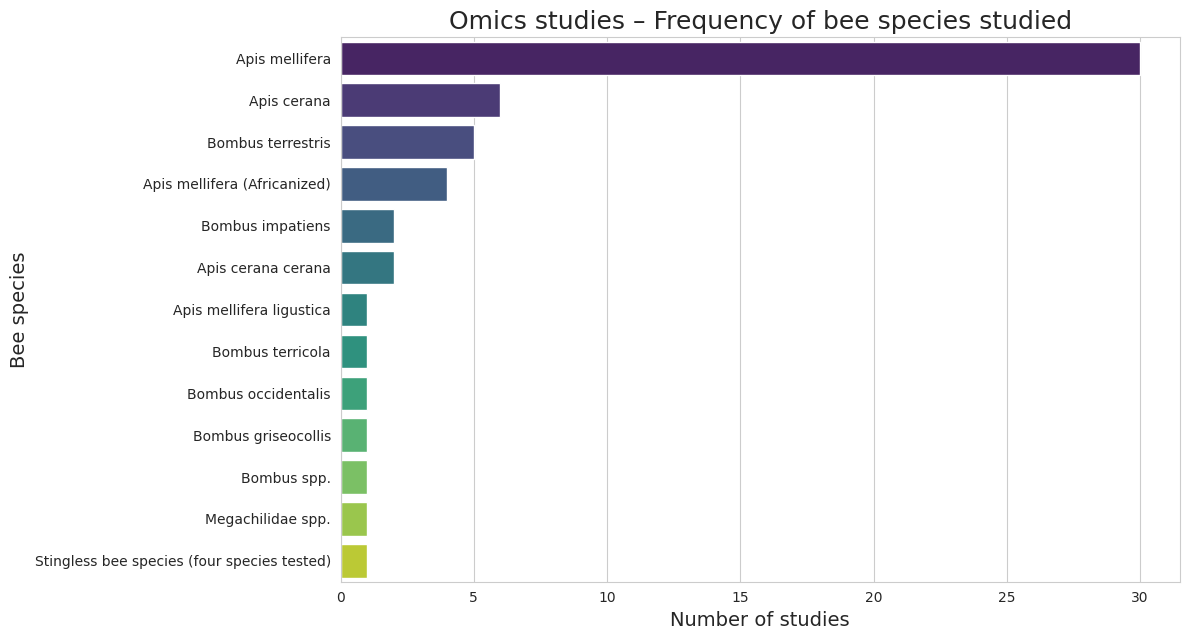

✅ Bar chart saved as 'Omics_Bee_Species_Frequency.png'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! The omics bee species frequency chart has been downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
Omics Dataset – Frequency of bee species studied
Upload your omics Excel file, and the script counts and plots bee species.
"""

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("="*60)
print("🐝  Omics – Frequency of bee species studied")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your Omics Excel file (e.g., final_list_selected_...Omics.xlsx)")
uploaded = files.upload()

if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: EXTRACT AND COUNT BEE SPECIES
# ============================================================================

def extract_species(entry):
    if pd.isna(entry):
        return []
    text = str(entry).replace(' and ', ' & ')
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        p = re.sub(r'\b(not reported|the|of|with|collaboration)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p and len(p) > 1:
            cleaned.append(p)
    return cleaned

all_species = []
for entry in df['Bee species']:
    all_species.extend(extract_species(entry))

species_counts = Counter(all_species)
species_counts.pop('Not reported', None)

species_df = pd.DataFrame(species_counts.items(), columns=['Species', 'Count'])
species_df = species_df.sort_values('Count', ascending=False)

# ============================================================================
# STEP 4: DISPLAY FREQUENCY TABLE
# ============================================================================

print("\n📊 Bee species frequencies (Omics dataset):")
print(species_df.to_string(index=False))
print(f"\n✅ Total unique species: {len(species_df)}")
print(f"✅ Total assignments: {species_df['Count'].sum()}")

# ============================================================================
# STEP 5: GENERATE BAR CHART
# ============================================================================

print("\n📊 Generating bar chart...")

top_n = min(20, len(species_df))
plot_df = species_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Species', palette='viridis')
plt.title('Omics studies – Frequency of bee species studied', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Bee species', fontsize=14)
plt.tight_layout()

chart_file = 'Omics_Bee_Species_Frequency.png'
plt.savefig(chart_file, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Bar chart saved as '{chart_file}'")

# ============================================================================
# STEP 6: DOWNLOAD THE CHART
# ============================================================================

files.download(chart_file)

print("\n🎉 Done! The omics bee species frequency chart has been downloaded.")

🐝  RT‑qPCR – Frequency of bee species studied

📤 Please upload your RT‑qPCR Excel file (e.g., Reviewd_papers_...RTqPCR.xlsx)


Saving Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (2).xlsx
✅ Uploaded: Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (2).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 190 rows from sheet 'Data_Extraction'.

📊 Bee species frequencies (RT‑qPCR dataset):
                                  Species  Count
                           Apis mellifera    163
                       Apis cerana cerana      7
                   Apis mellifera carnica      6
                              Apis cerana      4
                           Osmia bicornis      2
                 Apis mellifera lamarckii      1
                Apis mellifera iberiensis      1
         Apis mellifera cell line AmE-711      1
             Apis mellifera (Africanized)      1
                 Apis mellifera ligustica      1
               Nannotrigona perilampoides      1
                         Bombus impatiens      1
Bombus spp. (

/tmp/ipykernel_2200/2846711737.py:105: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




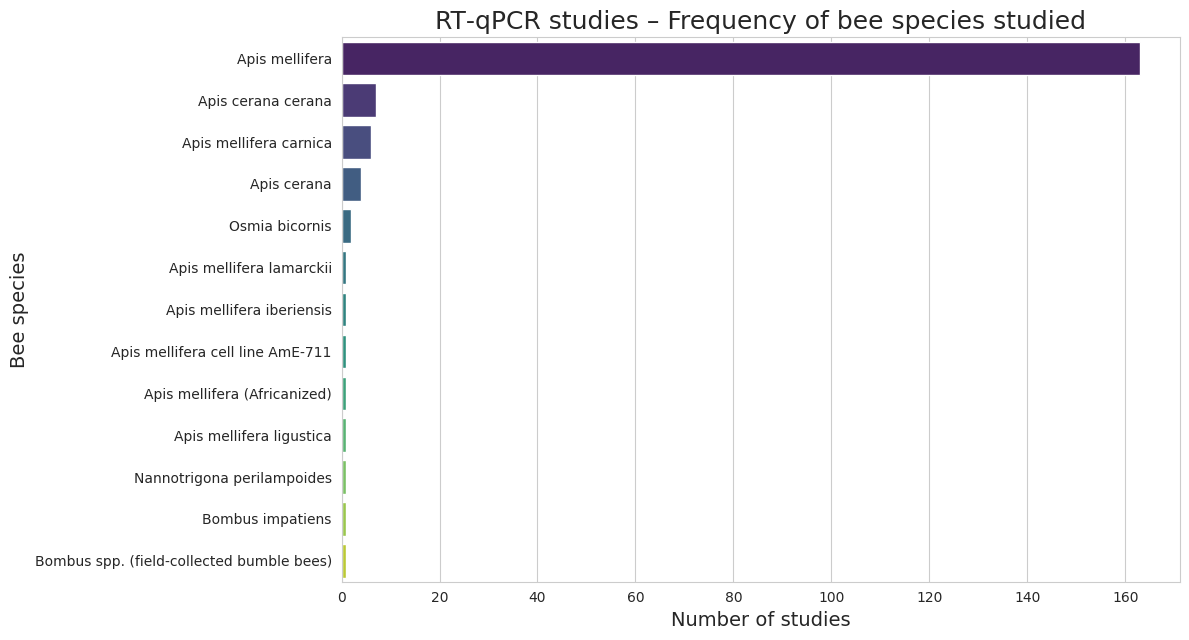

✅ Bar chart saved as 'RTPCR_Bee_Species_Frequency.png'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! The RT‑qPCR bee species frequency chart has been downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
RT‑qPCR Dataset – Frequency of bee species studied
Upload your RT‑qPCR Excel file, and the script counts and plots bee species.
"""

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("="*60)
print("🐝  RT‑qPCR – Frequency of bee species studied")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your RT‑qPCR Excel file (e.g., Reviewd_papers_...RTqPCR.xlsx)")
uploaded = files.upload()

if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: EXTRACT AND COUNT BEE SPECIES
# ============================================================================

def extract_species(entry):
    if pd.isna(entry):
        return []
    text = str(entry).replace(' and ', ' & ')
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        p = re.sub(r'\b(not reported|the|of|with|collaboration)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p and len(p) > 1:
            cleaned.append(p)
    return cleaned

all_species = []
for entry in df['Bee species']:
    all_species.extend(extract_species(entry))

species_counts = Counter(all_species)
species_counts.pop('Not reported', None)

species_df = pd.DataFrame(species_counts.items(), columns=['Species', 'Count'])
species_df = species_df.sort_values('Count', ascending=False)

# ============================================================================
# STEP 4: DISPLAY FREQUENCY TABLE
# ============================================================================

print("\n📊 Bee species frequencies (RT‑qPCR dataset):")
print(species_df.to_string(index=False))
print(f"\n✅ Total unique species: {len(species_df)}")
print(f"✅ Total assignments: {species_df['Count'].sum()}")

# ============================================================================
# STEP 5: GENERATE BAR CHART
# ============================================================================

print("\n📊 Generating bar chart...")

top_n = min(20, len(species_df))
plot_df = species_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Species', palette='viridis')
plt.title('RT‑qPCR studies – Frequency of bee species studied', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Bee species', fontsize=14)
plt.tight_layout()

chart_file = 'RTPCR_Bee_Species_Frequency.png'
plt.savefig(chart_file, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Bar chart saved as '{chart_file}'")

# ============================================================================
# STEP 6: DOWNLOAD THE CHART
# ============================================================================

files.download(chart_file)

print("\n🎉 Done! The RT‑qPCR bee species frequency chart has been downloaded.")

🧪  Omics – Pesticide classes & Active ingredients

📤 Please upload your Omics Excel file (e.g., final_list_selected_...Omics.xlsx)


Saving final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics.xlsx to final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics (2).xlsx
✅ Uploaded: final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics (2).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 53 rows from sheet 'Data_Extraction'.

📊 Pesticide class frequencies (Omics):
                 Pesticide Class  Count
                   Neonicotinoid     24
                        Triazole      4
                 Organophosphate      4
                      Pyrethroid      4
                        Spinosyn      3
                  Phenylpyrazole      3
                     Sulfoximine      2
                       Mesoionic      2
                      Butenolide      2
               glycine herbicide      2
                     Phosphonate      2
                             QoI      1
                     Strobilurin      1
        Botanical bioinsecticide      1
                         Diamide      1
     

/tmp/ipykernel_2200/3318616249.py:125: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




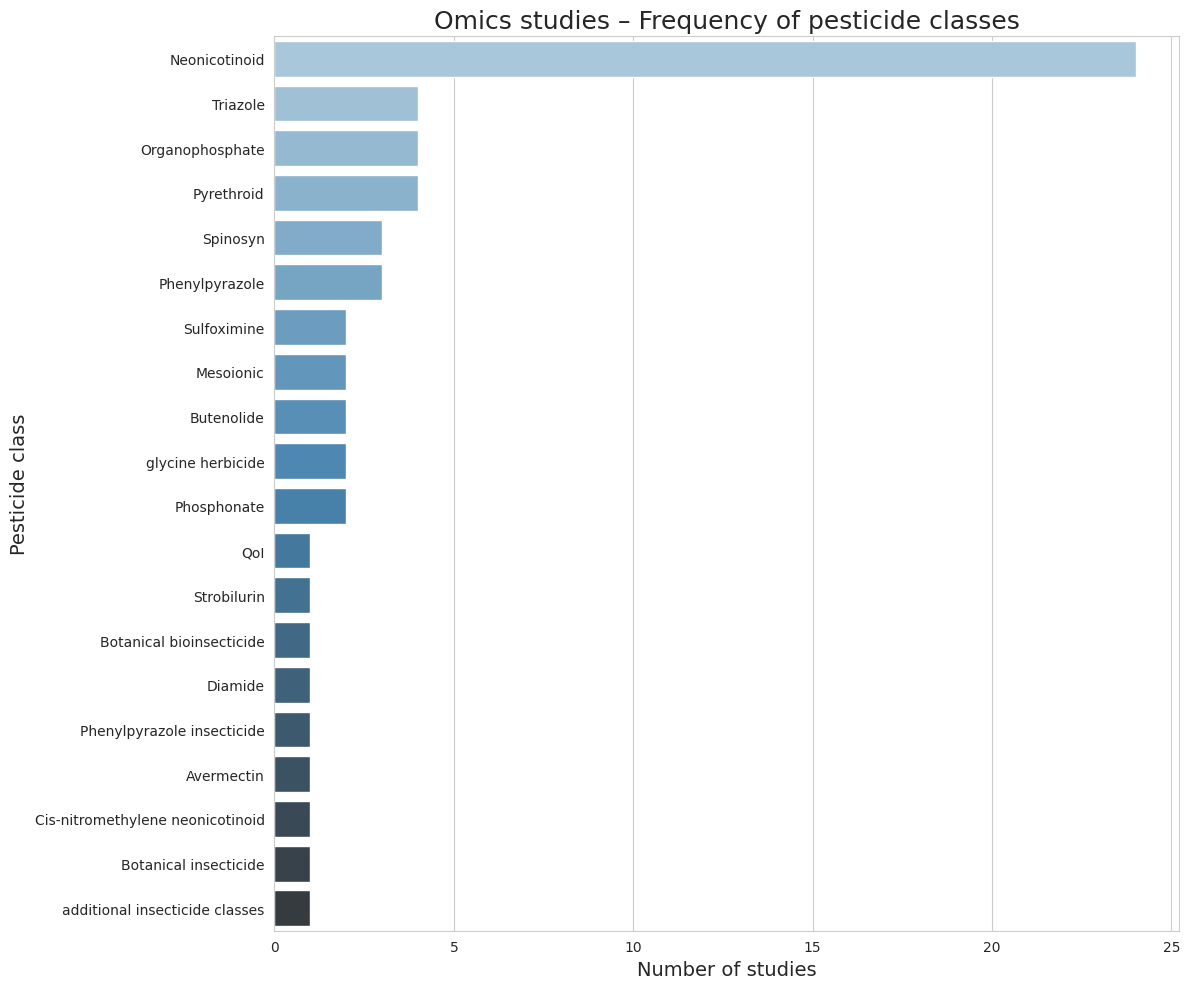

✅ Chart saved as 'Omics_Pesticide_Classes.png'

📊 Generating bar chart for active ingredients...


/tmp/ipykernel_2200/3318616249.py:142: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




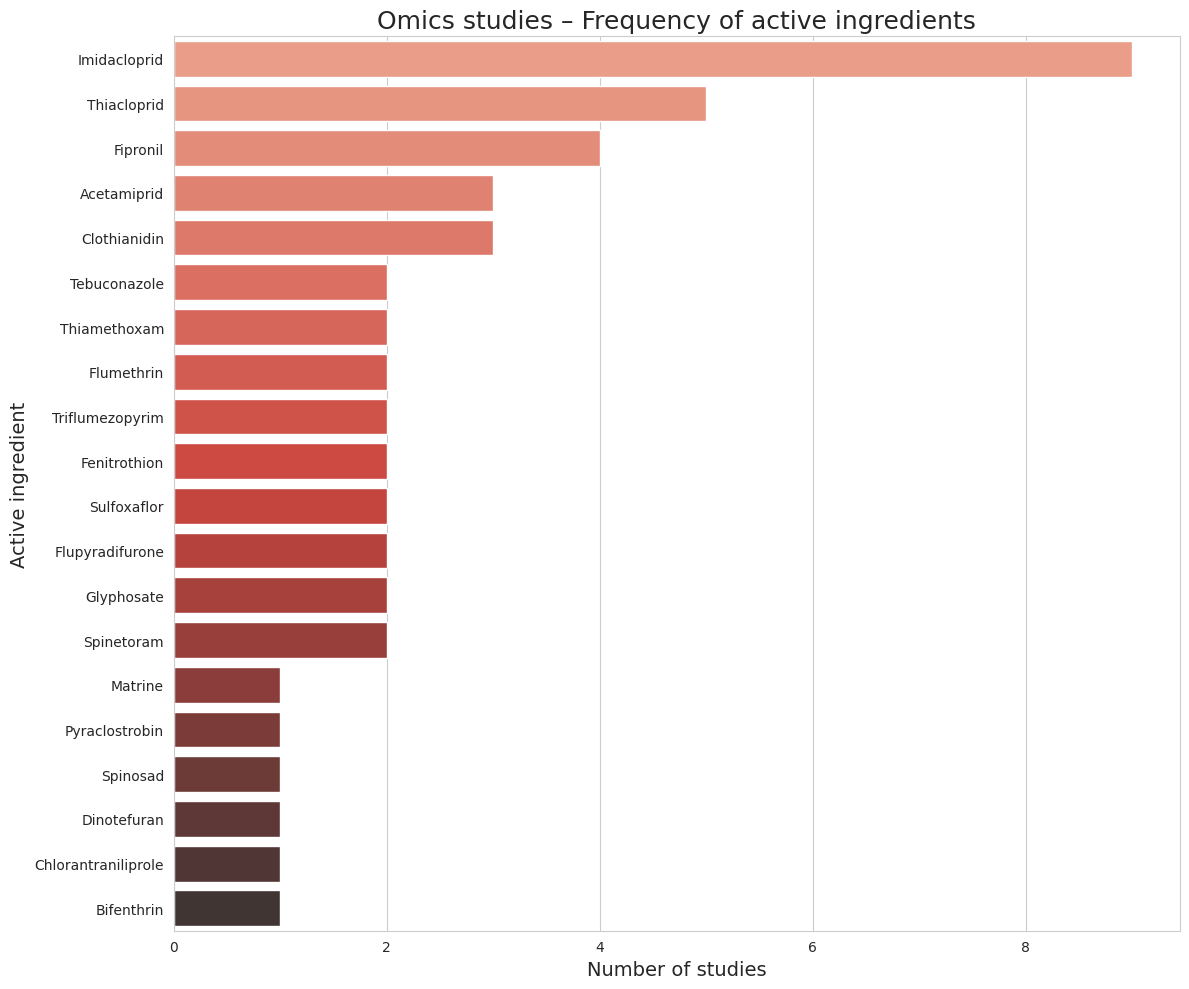

✅ Chart saved as 'Omics_Active_Ingredients.png'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! Both charts have been downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
Omics Dataset – Frequency of pesticide classes and active ingredients
Upload your omics Excel file, and the script counts and plots both.
"""

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("="*60)
print("🧪  Omics – Pesticide classes & Active ingredients")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your Omics Excel file (e.g., final_list_selected_...Omics.xlsx)")
uploaded = files.upload()

if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: DEFINE SPLITTING FUNCTION
# ============================================================================

def split_entries(entry):
    """Split string on ; , / &, clean and return list."""
    if pd.isna(entry):
        return []
    text = str(entry).replace(' and ', ' & ')
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        p = re.sub(r'\b(not reported|the|of|with|collaboration)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p and len(p) > 1:
            cleaned.append(p)
    return cleaned

# ============================================================================
# STEP 4: COUNT PESTICIDE CLASSES
# ============================================================================

all_classes = []
for entry in df['Pesticide class']:
    all_classes.extend(split_entries(entry))

class_counts = Counter(all_classes)
class_counts.pop('Not reported', None)

class_df = pd.DataFrame(class_counts.items(), columns=['Pesticide Class', 'Count'])
class_df = class_df.sort_values('Count', ascending=False)

print("\n📊 Pesticide class frequencies (Omics):")
print(class_df.to_string(index=False))
print(f"\n✅ Total unique classes: {len(class_df)}")
print(f"✅ Total assignments: {class_df['Count'].sum()}")

# ============================================================================
# STEP 5: COUNT ACTIVE INGREDIENTS (Pesticide column)
# ============================================================================

all_pesticides = []
for entry in df['Pesticide']:
    all_pesticides.extend(split_entries(entry))

pest_counts = Counter(all_pesticides)
pest_counts.pop('Not reported', None)

pest_df = pd.DataFrame(pest_counts.items(), columns=['Active Ingredient', 'Count'])
pest_df = pest_df.sort_values('Count', ascending=False)

print("\n📊 Active ingredient frequencies (Omics):")
print(pest_df.head(20).to_string(index=False))
print(f"\n✅ Total unique ingredients: {len(pest_df)}")
print(f"✅ Total assignments: {pest_df['Count'].sum()}")

# ============================================================================
# STEP 6: PLOT BAR CHARTS
# ============================================================================

# --- Plot Pesticide Classes ---
print("\n📊 Generating bar chart for pesticide classes...")
top_n = min(20, len(class_df))
plot_df = class_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Pesticide Class', palette='Blues_d')
plt.title('Omics studies – Frequency of pesticide classes', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Pesticide class', fontsize=14)
plt.tight_layout()

chart1 = 'Omics_Pesticide_Classes.png'
plt.savefig(chart1, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved as '{chart1}'")

# --- Plot Active Ingredients ---
print("\n📊 Generating bar chart for active ingredients...")
top_n = min(20, len(pest_df))
plot_df = pest_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Active Ingredient', palette='Reds_d')
plt.title('Omics studies – Frequency of active ingredients', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Active ingredient', fontsize=14)
plt.tight_layout()

chart2 = 'Omics_Active_Ingredients.png'
plt.savefig(chart2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved as '{chart2}'")

# ============================================================================
# STEP 7: DOWNLOAD CHARTS
# ============================================================================

files.download(chart1)
files.download(chart2)

print("\n🎉 Done! Both charts have been downloaded.")

🧪  RT‑qPCR – Pesticide classes & Active ingredients

📤 Please upload your RT‑qPCR Excel file (e.g., Reviewd_papers_...RTqPCR.xlsx)


Saving Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (3).xlsx
✅ Uploaded: Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (3).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 190 rows from sheet 'Data_Extraction'.

📊 Pesticide class frequencies (RT‑qPCR):
                             Pesticide Class  Count
                               Neonicotinoid     71
                             Organophosphate     16
                                  Pyrethroid     15
                                  Butenolide     12
                                    Triazole     11
                                         QoI     10
                                 Strobilurin      9
                                 Phosphonate      6
                           glycine herbicide      6
                                     Diamide      5
                              Phenylpyrazole      4
                    Neonicotin

/tmp/ipykernel_2200/3873042405.py:125: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




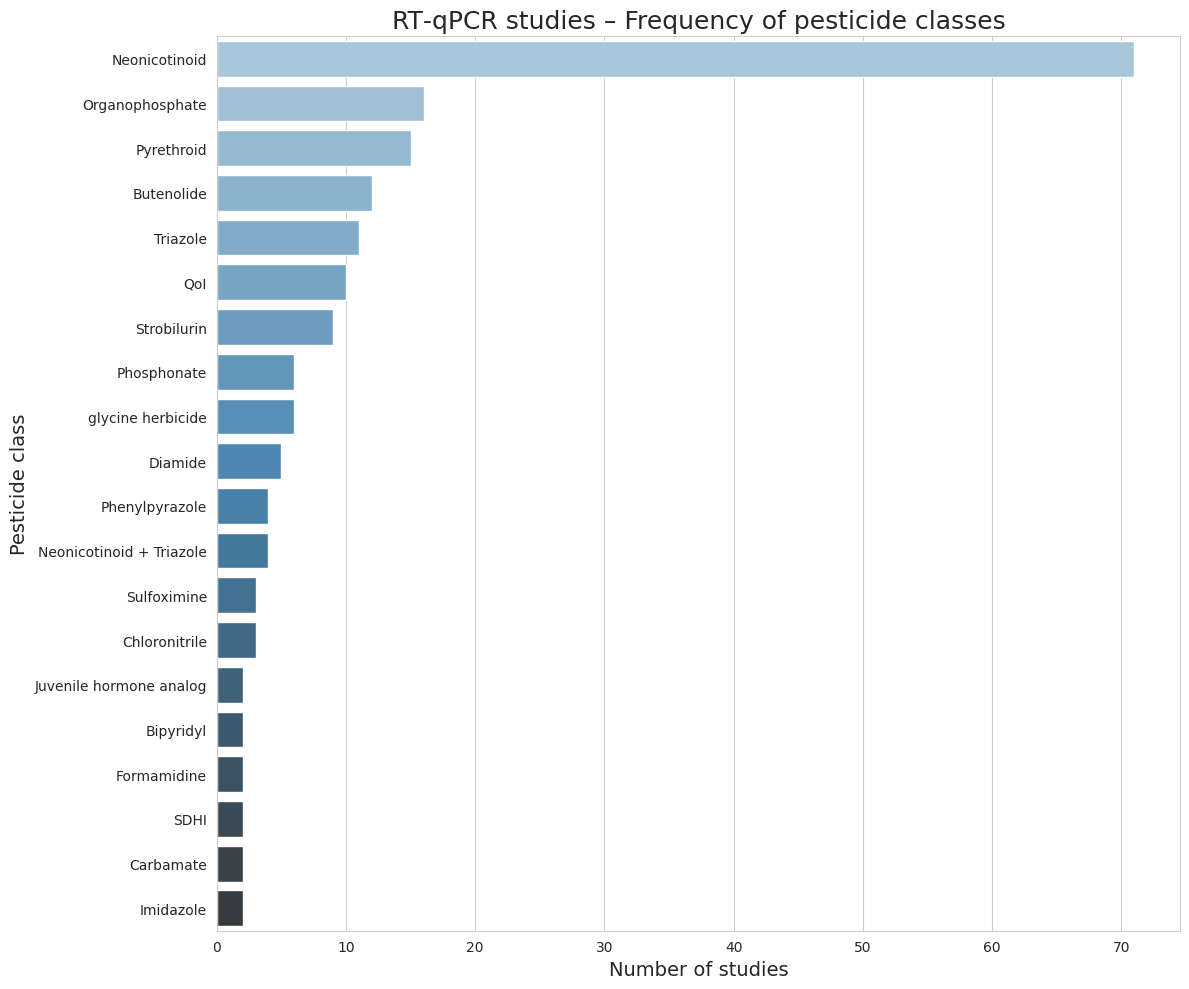

✅ Chart saved as 'RTPCR_Pesticide_Classes.png'

📊 Generating bar chart for active ingredients...


/tmp/ipykernel_2200/3873042405.py:142: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




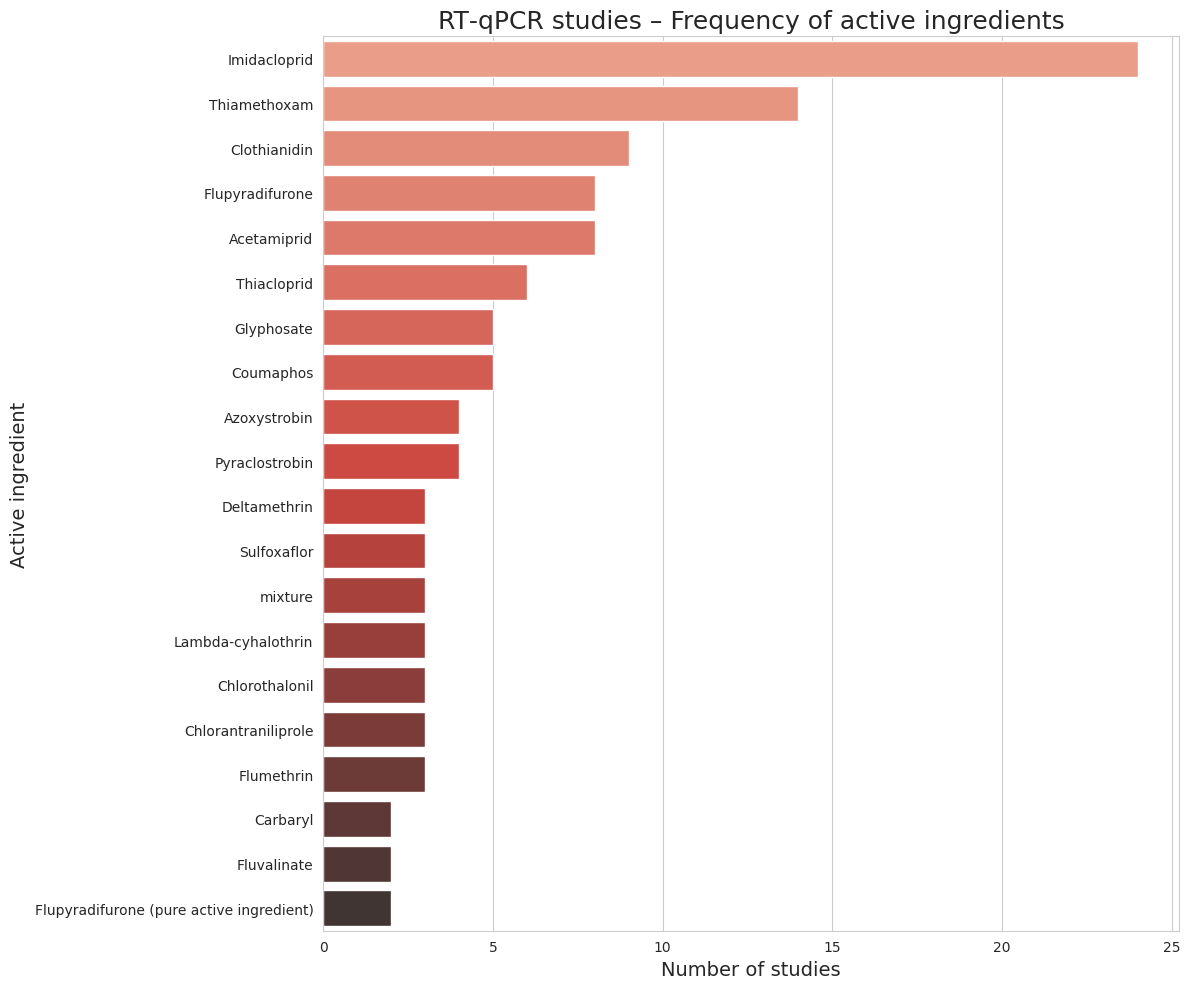

✅ Chart saved as 'RTPCR_Active_Ingredients.png'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! Both charts have been downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
RT‑qPCR Dataset – Frequency of pesticide classes and active ingredients
Upload your RT‑qPCR Excel file, and the script counts and plots both.
"""

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("="*60)
print("🧪  RT‑qPCR – Pesticide classes & Active ingredients")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your RT‑qPCR Excel file (e.g., Reviewd_papers_...RTqPCR.xlsx)")
uploaded = files.upload()

if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: DEFINE SPLITTING FUNCTION
# ============================================================================

def split_entries(entry):
    """Split string on ; , / &, clean and return list."""
    if pd.isna(entry):
        return []
    text = str(entry).replace(' and ', ' & ')
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        p = re.sub(r'\b(not reported|the|of|with|collaboration)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p and len(p) > 1:
            cleaned.append(p)
    return cleaned

# ============================================================================
# STEP 4: COUNT PESTICIDE CLASSES
# ============================================================================

all_classes = []
for entry in df['Pesticide class']:
    all_classes.extend(split_entries(entry))

class_counts = Counter(all_classes)
class_counts.pop('Not reported', None)

class_df = pd.DataFrame(class_counts.items(), columns=['Pesticide Class', 'Count'])
class_df = class_df.sort_values('Count', ascending=False)

print("\n📊 Pesticide class frequencies (RT‑qPCR):")
print(class_df.to_string(index=False))
print(f"\n✅ Total unique classes: {len(class_df)}")
print(f"✅ Total assignments: {class_df['Count'].sum()}")

# ============================================================================
# STEP 5: COUNT ACTIVE INGREDIENTS (Pesticide column)
# ============================================================================

all_pesticides = []
for entry in df['Pesticide']:
    all_pesticides.extend(split_entries(entry))

pest_counts = Counter(all_pesticides)
pest_counts.pop('Not reported', None)

pest_df = pd.DataFrame(pest_counts.items(), columns=['Active Ingredient', 'Count'])
pest_df = pest_df.sort_values('Count', ascending=False)

print("\n📊 Active ingredient frequencies (RT‑qPCR):")
print(pest_df.head(20).to_string(index=False))
print(f"\n✅ Total unique ingredients: {len(pest_df)}")
print(f"✅ Total assignments: {pest_df['Count'].sum()}")

# ============================================================================
# STEP 6: PLOT BAR CHARTS
# ============================================================================

# --- Plot Pesticide Classes ---
print("\n📊 Generating bar chart for pesticide classes...")
top_n = min(20, len(class_df))
plot_df = class_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Pesticide Class', palette='Blues_d')
plt.title('RT‑qPCR studies – Frequency of pesticide classes', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Pesticide class', fontsize=14)
plt.tight_layout()

chart1 = 'RTPCR_Pesticide_Classes.png'
plt.savefig(chart1, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved as '{chart1}'")

# --- Plot Active Ingredients ---
print("\n📊 Generating bar chart for active ingredients...")
top_n = min(20, len(pest_df))
plot_df = pest_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Active Ingredient', palette='Reds_d')
plt.title('RT‑qPCR studies – Frequency of active ingredients', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Active ingredient', fontsize=14)
plt.tight_layout()

chart2 = 'RTPCR_Active_Ingredients.png'
plt.savefig(chart2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved as '{chart2}'")

# ============================================================================
# STEP 7: DOWNLOAD CHARTS
# ============================================================================

files.download(chart1)
files.download(chart2)

print("\n🎉 Done! Both charts have been downloaded.")

🧪  Omics – Pesticide Classification Frequency

📤 Please upload your Omics Excel file (e.g., final_list_selected_...Omics.xlsx)


Saving final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics.xlsx to final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics (4).xlsx
✅ Uploaded: final_list_selected_Bee_Toxicogenomics_Data_Extraction_Omics (4).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 53 rows from sheet 'Data_Extraction'.

📊 Pesticide Classification frequencies (Omics dataset):
         Classification  Count
            Insecticide     43
              Fungicide      6
              Acaricide      4
               Miticide      3
              Herbicide      3
Insect growth regulator      1

✅ Total unique classifications: 6
✅ Total assignments (sum of counts): 60

📊 Generating bar chart...


/tmp/ipykernel_2200/3369587579.py:113: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




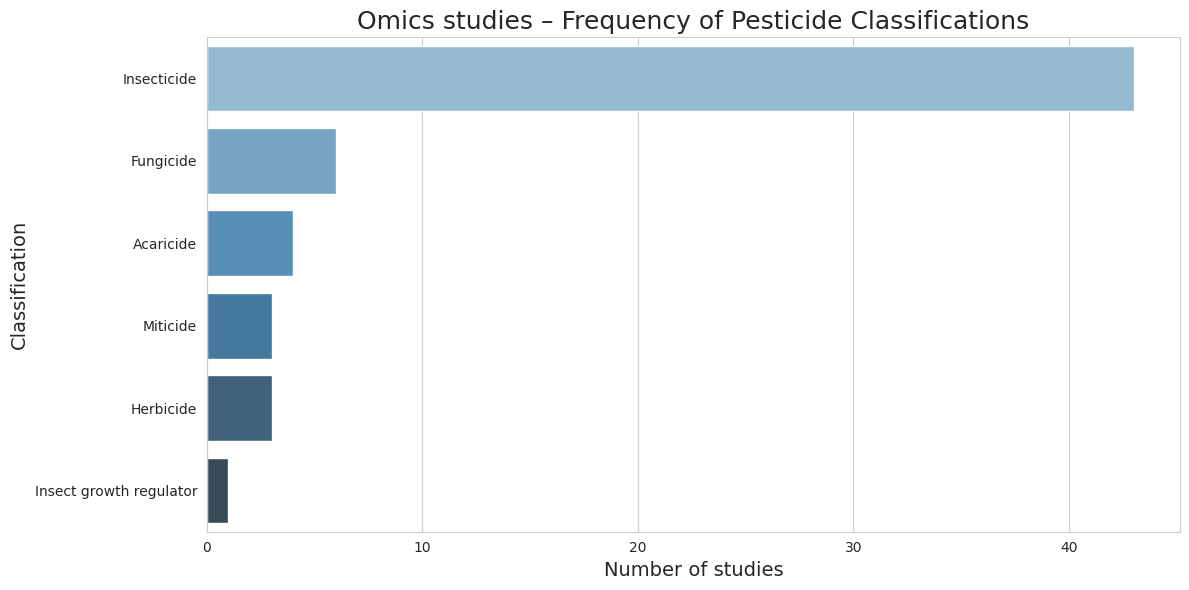

✅ Chart saved as 'Omics_Pesticide_Classification.png'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! The chart has been downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
Omics Dataset – Frequency of Pesticide Classifications
Counts studies by classification (Insecticide, Herbicide, Fungicide, etc.)
"""

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("="*60)
print("🧪  Omics – Pesticide Classification Frequency")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your Omics Excel file (e.g., final_list_selected_...Omics.xlsx)")
uploaded = files.upload()
if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: EXTRACT PESTICIDE CLASSIFICATIONS
# ============================================================================

# Check if column exists
col_name = 'Pesticide Classification (e.g., insecticide, herbicide, acaricide, miticide,  fungicide,…)'
if col_name not in df.columns:
    print("⚠️ Column 'Pesticide Classification' not found. Creating empty column.")
    df[col_name] = "Not reported"

def split_entries(entry):
    if pd.isna(entry):
        return []
    text = str(entry).replace(' and ', ' & ')
    # Split on ; , / &
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        # Remove noise
        p = re.sub(r'\b(not reported|the|of|with|collaboration)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p and len(p) > 1:
            cleaned.append(p)
    return cleaned

all_categories = []
for entry in df[col_name]:
    all_categories.extend(split_entries(entry))

# Remove any "Not reported" leftovers
all_categories = [c for c in all_categories if c.lower() != 'not reported']

# ============================================================================
# STEP 4: COUNT AND DISPLAY FREQUENCIES
# ============================================================================

counts = Counter(all_categories)
category_df = pd.DataFrame(counts.items(), columns=['Classification', 'Count'])
category_df = category_df.sort_values('Count', ascending=False)

print("\n📊 Pesticide Classification frequencies (Omics dataset):")
print(category_df.to_string(index=False))
print(f"\n✅ Total unique classifications: {len(category_df)}")
print(f"✅ Total assignments (sum of counts): {category_df['Count'].sum()}")

# ============================================================================
# STEP 5: GENERATE BAR CHART
# ============================================================================

print("\n📊 Generating bar chart...")

top_n = min(20, len(category_df))
plot_df = category_df.head(top_n)

plt.figure(figsize=(12, max(6, top_n * 0.5)))
sns.barplot(data=plot_df, x='Count', y='Classification', palette='Blues_d')
plt.title('Omics studies – Frequency of Pesticide Classifications', fontsize=18)
plt.xlabel('Number of studies', fontsize=14)
plt.ylabel('Classification', fontsize=14)
plt.tight_layout()

chart_file = 'Omics_Pesticide_Classification.png'
plt.savefig(chart_file, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved as '{chart_file}'")

# ============================================================================
# STEP 6: DOWNLOAD THE CHART
# ============================================================================

files.download(chart_file)

print("\n🎉 Done! The chart has been downloaded.")

🧪  RT‑qPCR – Pesticide Classification Frequency

📤 Please upload your RT‑qPCR Excel file (e.g., Reviewd_papers_...RTqPCR.xlsx)


Saving Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (7).xlsx
✅ Uploaded: Reviewd_papers_Bee_Toxicogenomics_Data_Extraction_RTqPCR (7).xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 190 rows from sheet 'Data_Extraction'.
✅ Using column: 'Pesticide Classification'

📊 Pesticide Classification frequencies (RT‑qPCR dataset):
                      Classification  Count
                         Insecticide    115
                           Fungicide     30
                           Acaricide     30
                            Miticide     23
                           Herbicide     10
             Insecticide + Fungicide      5
                    Mixed pesticides      3
             Insect growth regulator      3
                 Acaricide candidate      2
              Plant growth regulator      1
Insecticide + Plant growth regulator      1
               Acaricide + Fungicide      1
                Mitici

/tmp/ipykernel_2200/2773817708.py:130: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




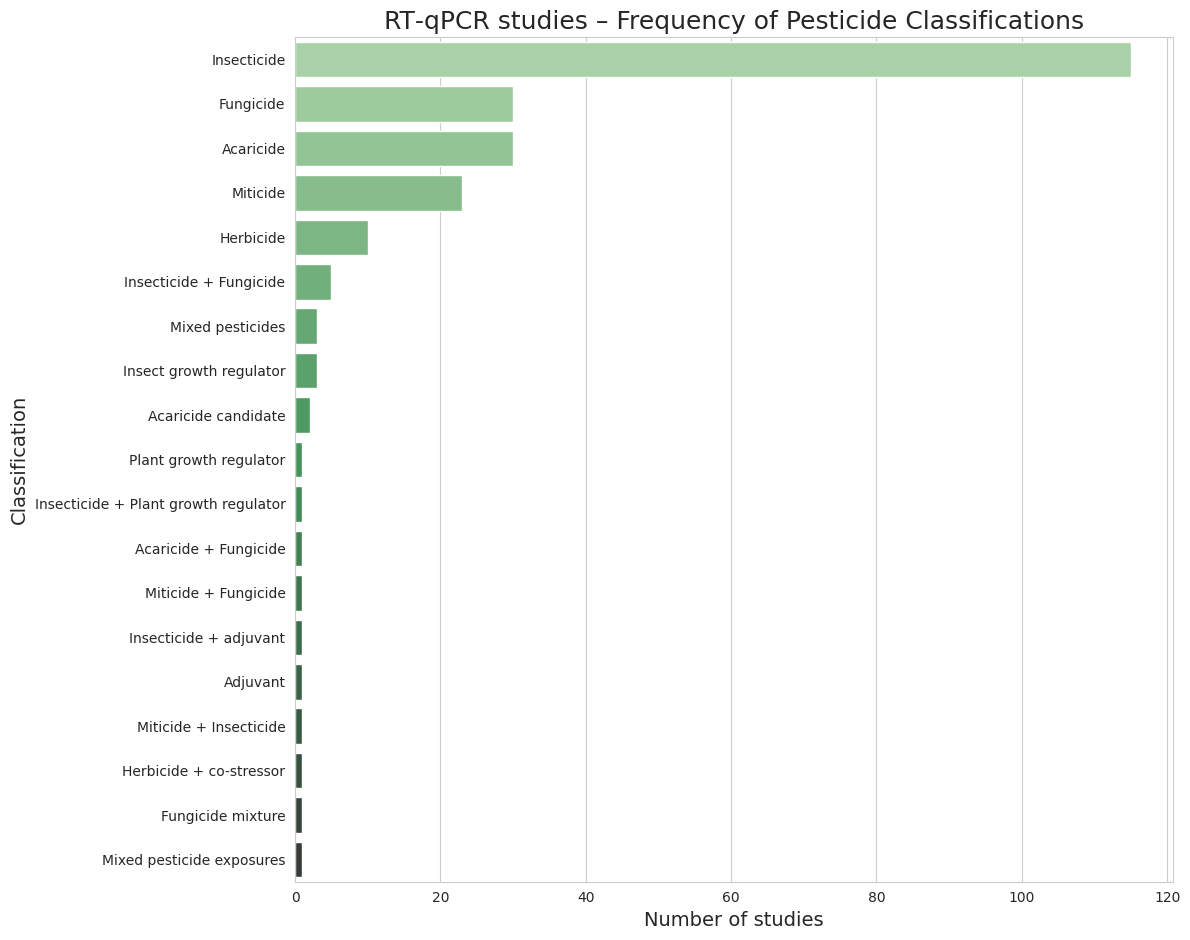

✅ Chart saved as 'RTPCR_Pesticide_Classification.png'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! The chart has been downloaded.


In [ ]:
# -*- coding: utf-8 -*-
"""
RT‑qPCR Dataset – Frequency of Pesticide Classifications
Correct column name: 'Pesticide Classification' (short version)
"""

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("="*60)
print("🧪  RT‑qPCR – Pesticide Classification Frequency")
print("="*60)

# ============================================================================
# STEP 1: UPLOAD THE EXCEL FILE
# ============================================================================

print("\n📤 Please upload your RT‑qPCR Excel file (e.g., Reviewd_papers_...RTqPCR.xlsx)")
uploaded = files.upload()
if not uploaded:
    raise SystemExit("No file uploaded. Exiting.")

FILE_PATH = list(uploaded.keys())[0]
print(f"✅ Uploaded: {FILE_PATH}")

# ============================================================================
# STEP 2: READ THE EXCEL FILE (auto-detect sheet)
# ============================================================================

xl = pd.ExcelFile(FILE_PATH)
sheet_names = xl.sheet_names
print(f"📄 Available sheets: {sheet_names}")

target_sheet = None
for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
    if candidate in sheet_names:
        target_sheet = candidate
        break
if target_sheet is None:
    target_sheet = sheet_names[0]
    print(f"Using first sheet: {target_sheet}")

df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
df.columns = df.columns.str.strip()
print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")

# ============================================================================
# STEP 3: IDENTIFY THE CORRECT COLUMN
# ============================================================================

# The RT‑qPCR file uses the short column name
col_candidates = [
    'Pesticide Classification',
    'Pesticide Classification (e.g., insecticide, herbicide, acaricide, miticide,  fungicide,…)'
]
col_found = None
for col in col_candidates:
    if col in df.columns:
        col_found = col
        break

if col_found is None:
    print("⚠️ Pesticide Classification column not found. Available columns:")
    print(df.columns.tolist())
    raise SystemExit("Cannot proceed without the classification column.")

print(f"✅ Using column: '{col_found}'")

# ============================================================================
# STEP 4: EXTRACT PESTICIDE CLASSIFICATIONS
# ============================================================================

def split_entries(entry):
    if pd.isna(entry):
        return []
    text = str(entry).replace(' and ', ' & ')
    parts = re.split(r'[;,/&]+', text)
    cleaned = []
    for p in parts:
        p = p.strip()
        if not p:
            continue
        p = re.sub(r'\b(not reported|the|of|with|collaboration)\b', '', p, flags=re.IGNORECASE)
        p = p.strip()
        if p and len(p) > 1:
            cleaned.append(p)
    return cleaned

all_categories = []
for entry in df[col_found]:
    all_categories.extend(split_entries(entry))

# Remove any "Not reported" leftovers
all_categories = [c for c in all_categories if c.lower() != 'not reported']

# ============================================================================
# STEP 5: COUNT AND DISPLAY FREQUENCIES
# ============================================================================

counts = Counter(all_categories)
category_df = pd.DataFrame(counts.items(), columns=['Classification', 'Count'])
category_df = category_df.sort_values('Count', ascending=False)

print("\n📊 Pesticide Classification frequencies (RT‑qPCR dataset):")
print(category_df.to_string(index=False))
print(f"\n✅ Total unique classifications: {len(category_df)}")
print(f"✅ Total assignments (sum of counts): {category_df['Count'].sum()}")

# ============================================================================
# STEP 6: GENERATE BAR CHART
# ============================================================================

print("\n📊 Generating bar chart...")

if category_df.empty:
    print("⚠️ No data to plot. Check if 'Pesticide Classification' column contains values.")
else:
    top_n = min(20, len(category_df))
    plot_df = category_df.head(top_n)

    plt.figure(figsize=(12, max(6, top_n * 0.5)))
    sns.barplot(data=plot_df, x='Count', y='Classification', palette='Greens_d')
    plt.title('RT‑qPCR studies – Frequency of Pesticide Classifications', fontsize=18)
    plt.xlabel('Number of studies', fontsize=14)
    plt.ylabel('Classification', fontsize=14)
    plt.tight_layout()

    chart_file = 'RTPCR_Pesticide_Classification.png'
    plt.savefig(chart_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Chart saved as '{chart_file}'")
    files.download(chart_file)

print("\n🎉 Done! The chart has been downloaded.")

✅ Publication-ready figures saved:
   - Molecular_Gene_Panel_Flowchart.png (600 DPI)
   - Molecular_Gene_Panel_Flowchart.pdf (Vector)
   - Molecular_Gene_Panel_Flowchart.svg (Vector)


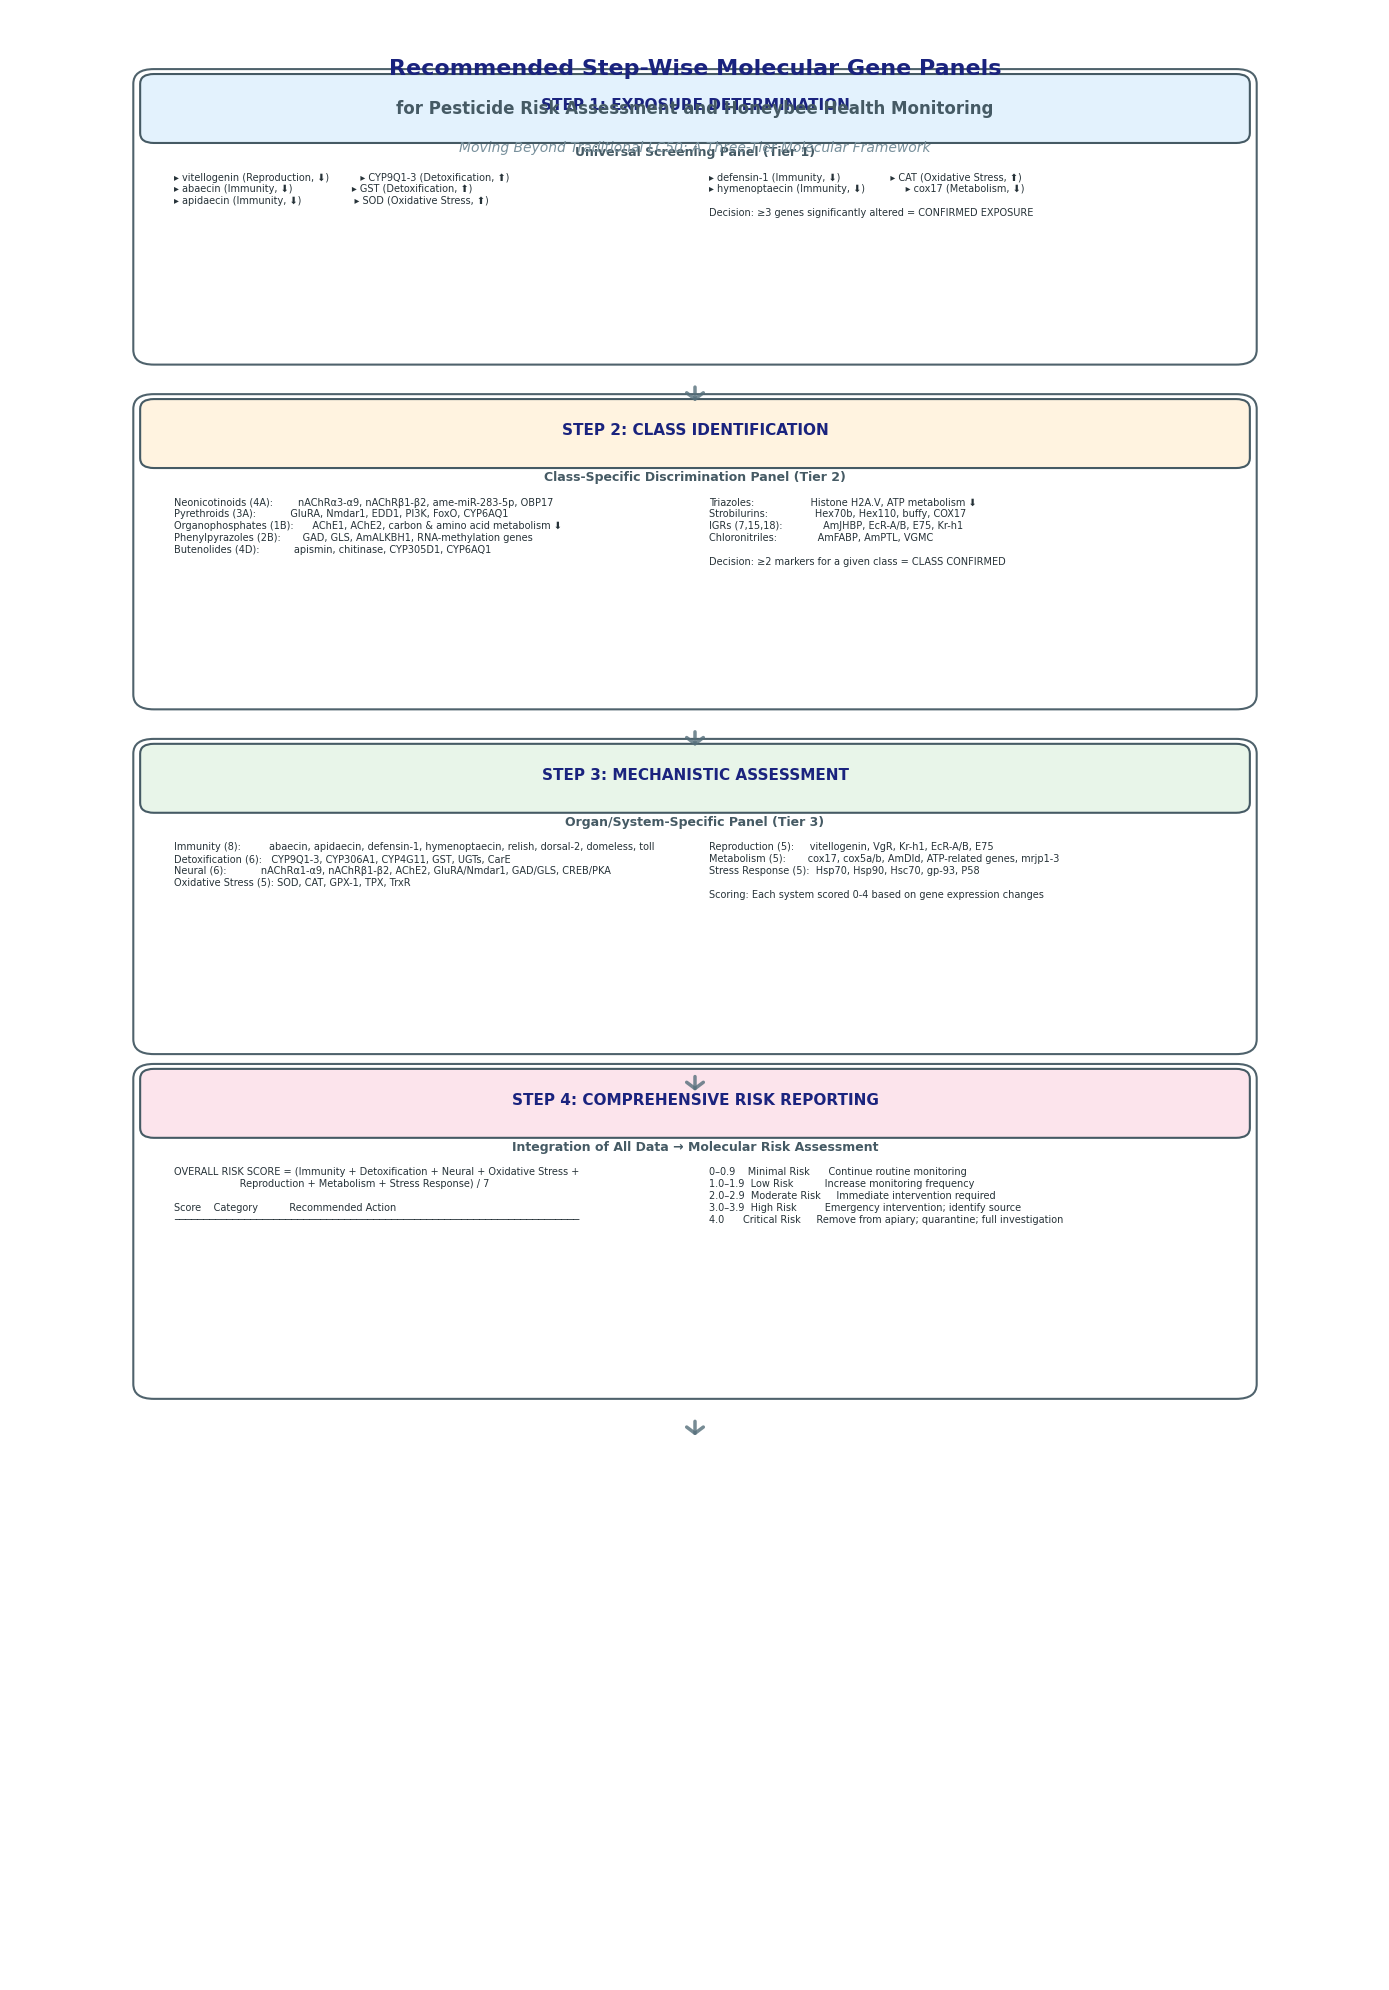

In [ ]:
# Molecular Gene Panels for Pesticide Risk Assessment in Honeybees
# Publication-Ready Flowchart Generator

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

# Set publication-quality parameters
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['patch.force_edgecolor'] = True

# Create figure and axis
fig, ax = plt.subplots(1, 1, figsize=(14, 20))
ax.set_xlim(0, 10)
ax.set_ylim(0, 20)
ax.axis('off')

# Define colors
colors = {
    'step1': '#E3F2FD',   # Light blue
    'step2': '#FFF3E0',   # Light orange
    'step3': '#E8F5E9',   # Light green
    'step4': '#FCE4EC',   # Light pink
    'title': '#1A237E',
    'subtitle': '#37474F',
    'border': '#455A64',
    'arrow': '#546E7A'
}

# ============================================================
# HELPER FUNCTION: Create a step box with title and content
# ============================================================

def create_step_box(ax, x, y, width, height, title, subtitle, content_lines,
                    header_color, body_color, border_color='#455A64', title_color='#1A237E'):
    """
    Create a step box with title, subtitle and content.
    """
    # Draw the main box
    box = FancyBboxPatch((x, y), width, height,
                         boxstyle="round,pad=0.1,rounding_size=0.15",
                         facecolor=body_color, edgecolor=border_color,
                         linewidth=1.5, alpha=0.95)
    ax.add_patch(box)

    # Draw the header
    header_height = 0.6
    header_box = FancyBboxPatch((x, y + height - header_height), width, header_height,
                                boxstyle="round,pad=0.05,rounding_size=0.1",
                                facecolor=header_color, edgecolor=border_color,
                                linewidth=1.5)
    ax.add_patch(header_box)

    # Title
    ax.text(x + width/2, y + height - header_height/2 + 0.03, title,
            fontsize=11, fontweight='bold', color=title_color,
            ha='center', va='center')

    # Subtitle
    ax.text(x + width/2, y + height - header_height - 0.08, subtitle,
            fontsize=9, fontweight='bold', color='#455A64',
            ha='center', va='top')

    # Content
    if content_lines:
        # Calculate start position for content
        content_y = y + height - header_height - 0.35

        # Determine if we should use columns for gene lists
        max_line_len = max([len(line) for line in content_lines]) if content_lines else 0

        if max_line_len > 45:
            # Use two columns for longer content
            mid_point = len(content_lines) // 2
            col1 = content_lines[:mid_point]
            col2 = content_lines[mid_point:]

            for i, line in enumerate(col1):
                ax.text(x + 0.2, content_y - i*0.12, line,
                        fontsize=7, color='#263238',
                        ha='left', va='top', linespacing=1.2)

            for i, line in enumerate(col2):
                ax.text(x + width/2 + 0.1, content_y - i*0.12, line,
                        fontsize=7, color='#263238',
                        ha='left', va='top', linespacing=1.2)
        else:
            # Single column
            for i, line in enumerate(content_lines):
                ax.text(x + width/2, content_y - i*0.12, line,
                        fontsize=7.5, color='#263238',
                        ha='center', va='top', linespacing=1.2)


# ============================================================
# STEP 1: EXPOSURE DETERMINATION
# ============================================================

step1_content = [
    "▸ vitellogenin (Reproduction, ⬇)          ▸ CYP9Q1-3 (Detoxification, ⬆)",
    "▸ abaecin (Immunity, ⬇)                   ▸ GST (Detoxification, ⬆)",
    "▸ apidaecin (Immunity, ⬇)                 ▸ SOD (Oxidative Stress, ⬆)",
    "▸ defensin-1 (Immunity, ⬇)                ▸ CAT (Oxidative Stress, ⬆)",
    "▸ hymenoptaecin (Immunity, ⬇)             ▸ cox17 (Metabolism, ⬇)",
    "",
    "Decision: ≥3 genes significantly altered = CONFIRMED EXPOSURE"
]

create_step_box(
    ax, x=1.0, y=16.5, width=8.0, height=2.8,
    title="STEP 1: EXPOSURE DETERMINATION",
    subtitle="Universal Screening Panel (Tier 1)",
    content_lines=step1_content,
    header_color=colors['step1'],
    body_color='white',
    title_color=colors['title']
)


# ============================================================
# STEP 2: CLASS IDENTIFICATION
# ============================================================

step2_content = [
    "Neonicotinoids (4A):        nAChRα3-α9, nAChRβ1-β2, ame-miR-283-5p, OBP17",
    "Pyrethroids (3A):           GluRA, Nmdar1, EDD1, PI3K, FoxO, CYP6AQ1",
    "Organophosphates (1B):      AChE1, AChE2, carbon & amino acid metabolism ⬇",
    "Phenylpyrazoles (2B):       GAD, GLS, AmALKBH1, RNA-methylation genes",
    "Butenolides (4D):           apismin, chitinase, CYP305D1, CYP6AQ1",
    "Triazoles:                  Histone H2A.V, ATP metabolism ⬇",
    "Strobilurins:               Hex70b, Hex110, buffy, COX17",
    "IGRs (7,15,18):             AmJHBP, EcR-A/B, E75, Kr-h1",
    "Chloronitriles:             AmFABP, AmPTL, VGMC",
    "",
    "Decision: ≥2 markers for a given class = CLASS CONFIRMED"
]

create_step_box(
    ax, x=1.0, y=13.0, width=8.0, height=3.0,
    title="STEP 2: CLASS IDENTIFICATION",
    subtitle="Class-Specific Discrimination Panel (Tier 2)",
    content_lines=step2_content,
    header_color=colors['step2'],
    body_color='white',
    title_color=colors['title']
)


# ============================================================
# STEP 3: MECHANISTIC ASSESSMENT
# ============================================================

step3_content = [
    "Immunity (8):         abaecin, apidaecin, defensin-1, hymenoptaecin, relish, dorsal-2, domeless, toll",
    "Detoxification (6):   CYP9Q1-3, CYP306A1, CYP4G11, GST, UGTs, CarE",
    "Neural (6):           nAChRα1-α9, nAChRβ1-β2, AChE2, GluRA/Nmdar1, GAD/GLS, CREB/PKA",
    "Oxidative Stress (5): SOD, CAT, GPX-1, TPX, TrxR",
    "Reproduction (5):     vitellogenin, VgR, Kr-h1, EcR-A/B, E75",
    "Metabolism (5):       cox17, cox5a/b, AmDld, ATP-related genes, mrjp1-3",
    "Stress Response (5):  Hsp70, Hsp90, Hsc70, gp-93, P58",
    "",
    "Scoring: Each system scored 0-4 based on gene expression changes"
]

create_step_box(
    ax, x=1.0, y=9.5, width=8.0, height=3.0,
    title="STEP 3: MECHANISTIC ASSESSMENT",
    subtitle="Organ/System-Specific Panel (Tier 3)",
    content_lines=step3_content,
    header_color=colors['step3'],
    body_color='white',
    title_color=colors['title']
)


# ============================================================
# STEP 4: COMPREHENSIVE RISK REPORTING
# ============================================================

step4_content = [
    "OVERALL RISK SCORE = (Immunity + Detoxification + Neural + Oxidative Stress +",
    "                     Reproduction + Metabolism + Stress Response) / 7",
    "",
    "Score    Category          Recommended Action",
    "─────────────────────────────────────────────────────────────────────",
    "0–0.9    Minimal Risk      Continue routine monitoring",
    "1.0–1.9  Low Risk          Increase monitoring frequency",
    "2.0–2.9  Moderate Risk     Immediate intervention required",
    "3.0–3.9  High Risk         Emergency intervention; identify source",
    "4.0      Critical Risk     Remove from apiary; quarantine; full investigation"
]

create_step_box(
    ax, x=1.0, y=6.0, width=8.0, height=3.2,
    title="STEP 4: COMPREHENSIVE RISK REPORTING",
    subtitle="Integration of All Data → Molecular Risk Assessment",
    content_lines=step4_content,
    header_color=colors['step4'],
    body_color='white',
    title_color=colors['title']
)


# ============================================================
# ARROWS BETWEEN STEPS
# ============================================================

def draw_arrow(ax, x, y1, y2):
    arrow = FancyArrowPatch((x, y1), (x, y2),
                            arrowstyle='->,head_width=0.2,head_length=0.15',
                            mutation_scale=30, color=colors['arrow'],
                            linewidth=2.5, alpha=0.8)
    ax.add_patch(arrow)

draw_arrow(ax, 5.0, 16.2, 16.0)
draw_arrow(ax, 5.0, 12.7, 12.5)
draw_arrow(ax, 5.0, 9.2, 9.0)
draw_arrow(ax, 5.0, 5.7, 5.5)


# ============================================================
# TITLE
# ============================================================

ax.text(5.0, 19.4, "Recommended Step-Wise Molecular Gene Panels",
        fontsize=16, fontweight='bold', color=colors['title'],
        ha='center', va='center')

ax.text(5.0, 19.0, "for Pesticide Risk Assessment and Honeybee Health Monitoring",
        fontsize=12, fontweight='bold', color='#455A64',
        ha='center', va='center')

# Add subtitle
ax.text(5.0, 18.6, "Moving Beyond Traditional LC50: A Three-Tier Molecular Framework",
        fontsize=10, fontstyle='italic', color='#78909C',
        ha='center', va='center')


# ============================================================
# SAVE FIGURE
# ============================================================

plt.tight_layout()

# Save as high-resolution PNG
plt.savefig('Molecular_Gene_Panel_Flowchart.png',
            dpi=600, bbox_inches='tight', facecolor='white')

# Save as PDF for publication
plt.savefig('Molecular_Gene_Panel_Flowchart.pdf',
            dpi=600, bbox_inches='tight', facecolor='white')

# Save as SVG for vector editing
plt.savefig('Molecular_Gene_Panel_Flowchart.svg',
            dpi=600, bbox_inches='tight', facecolor='white')

print("✅ Publication-ready figures saved:")
print("   - Molecular_Gene_Panel_Flowchart.png (600 DPI)")
print("   - Molecular_Gene_Panel_Flowchart.pdf (Vector)")
print("   - Molecular_Gene_Panel_Flowchart.svg (Vector)")

# Display in Colab
plt.show()

✅ Publication-ready figures saved:
   - Molecular_Gene_Panel_Infographic.png (600 DPI)
   - Molecular_Gene_Panel_Infographic.pdf (Vector)
   - Molecular_Gene_Panel_Infographic.svg (Vector)


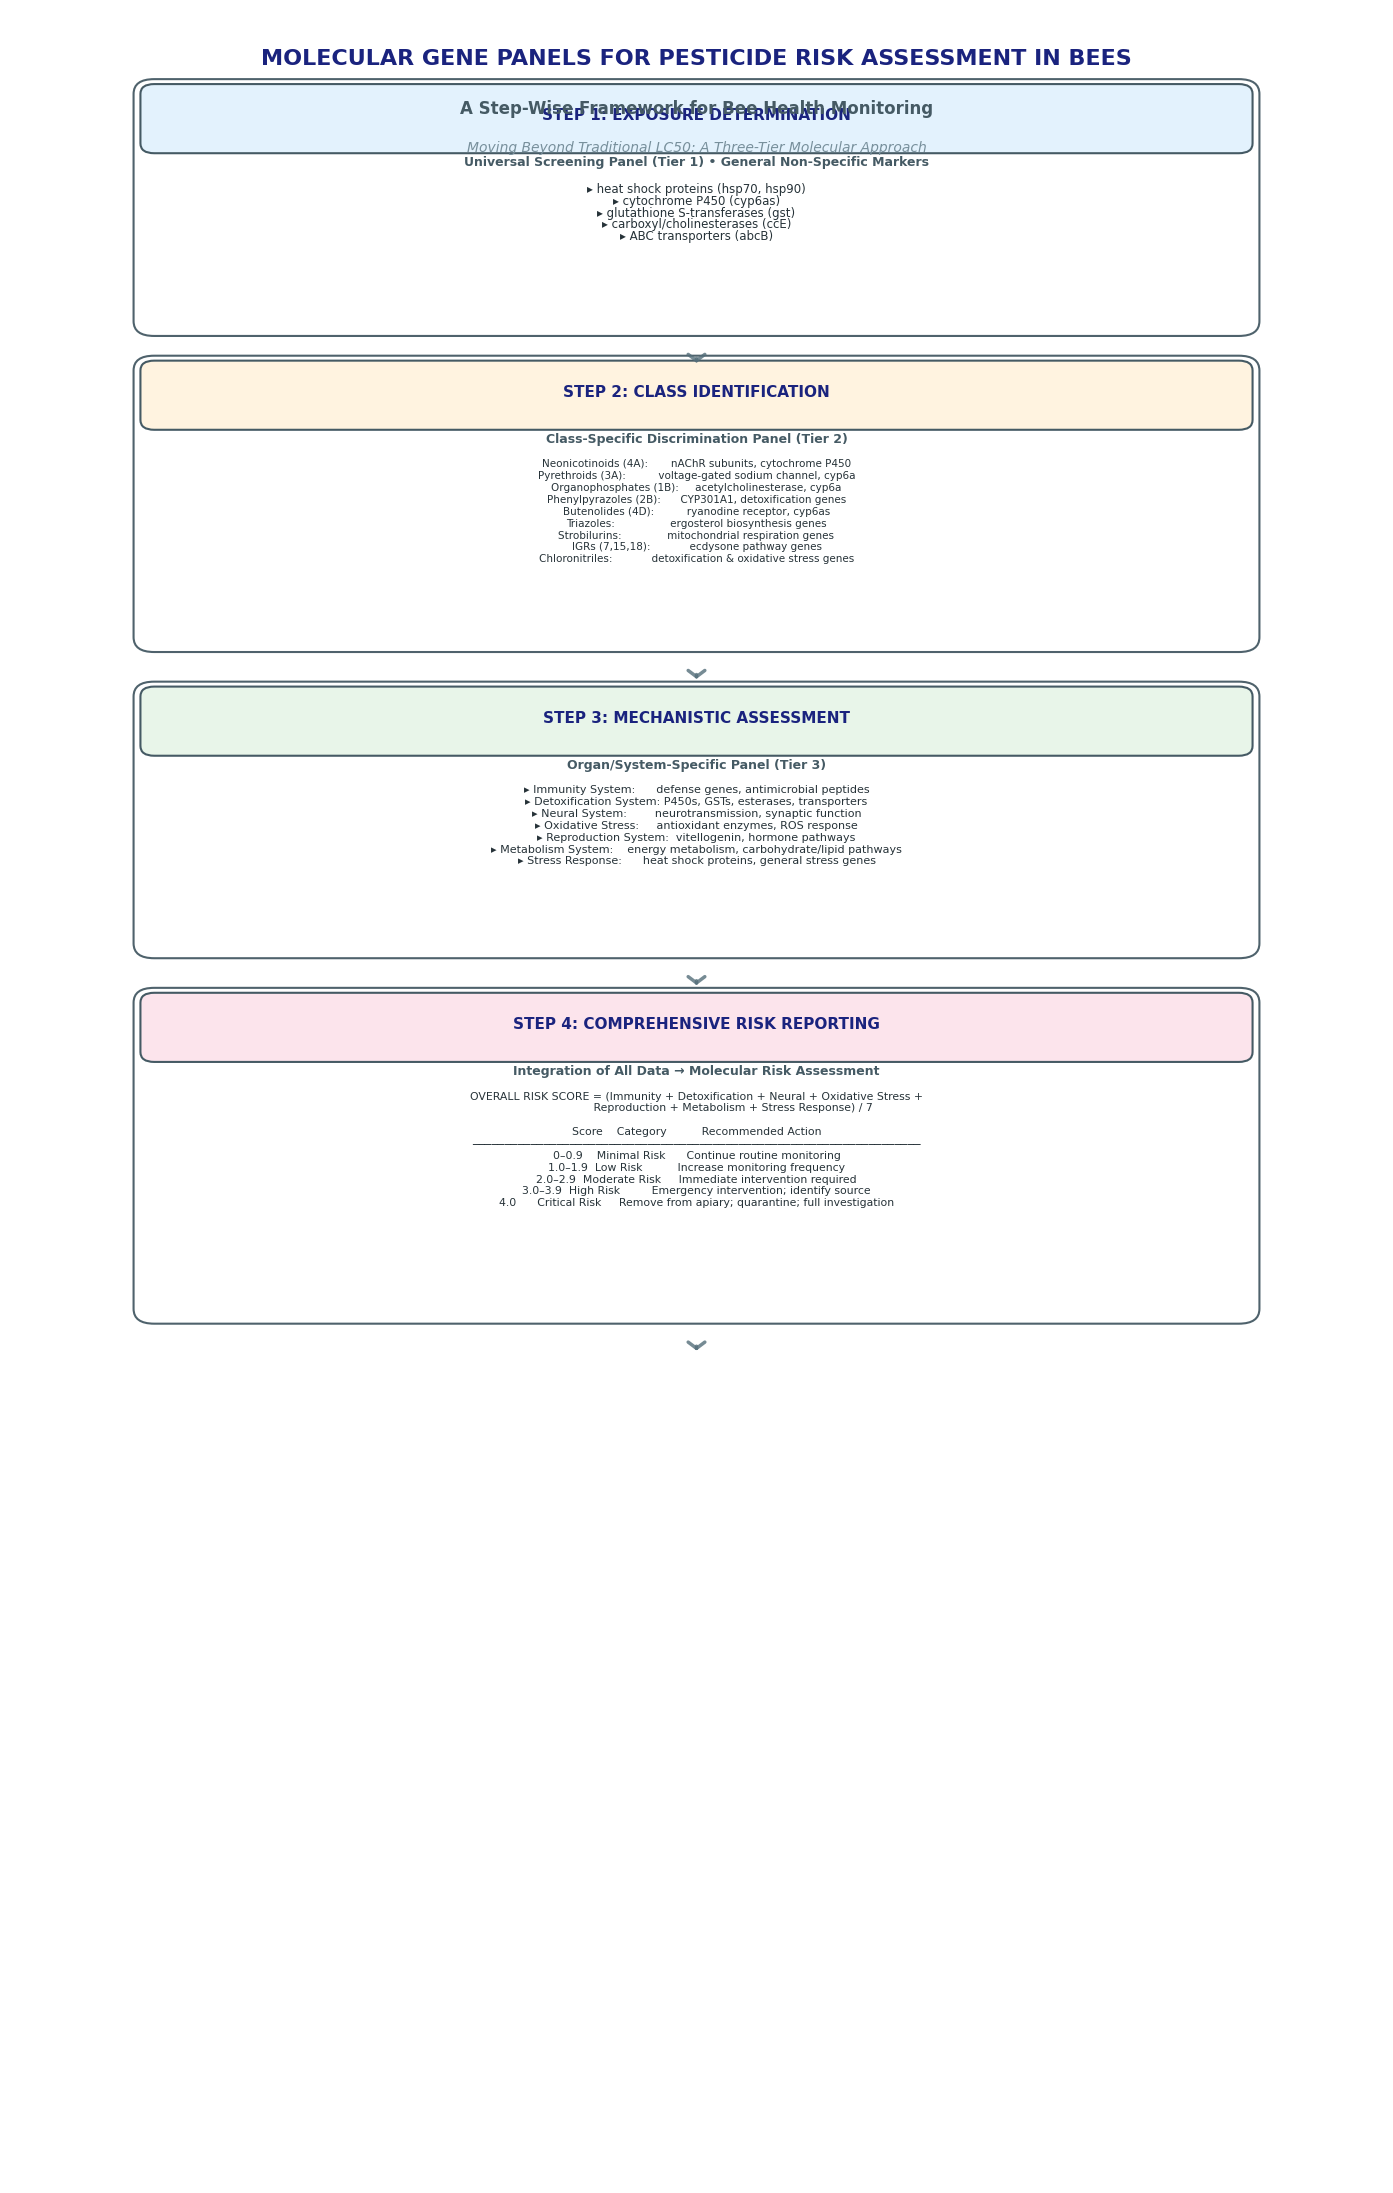

In [1]:
# Molecular Gene Panels for Pesticide Risk Assessment in Bees
# Publication-Ready Infographic Generator
# Run this in Google Colab

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

# Set publication-quality parameters
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 9
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['patch.force_edgecolor'] = True

# Create figure and axis (adjust size for content)
fig, ax = plt.subplots(1, 1, figsize=(14, 22))
ax.set_xlim(0, 10)
ax.set_ylim(0, 22)
ax.axis('off')

# Define colors
colors = {
    'step1': '#E3F2FD',   # Light blue
    'step2': '#FFF3E0',   # Light orange
    'step3': '#E8F5E9',   # Light green
    'step4': '#FCE4EC',   # Light pink
    'title': '#1A237E',
    'subtitle': '#37474F',
    'border': '#455A64',
    'arrow': '#546E7A',
    'accent': '#0D47A1'
}

# ============================================================
# HELPER FUNCTION: Create a step box with title, subtitle, content
# ============================================================

def create_step_box(ax, x, y, width, height, title, subtitle, content_lines,
                    header_color, body_color='white', border_color='#455A64',
                    title_color='#1A237E', fontsize_content=7.5, title_size=11,
                    subtitle_size=9, columns=1):
    """
    Create a step box with title, subtitle and content.
    If columns=2, split content into two columns.
    """
    # Draw the main box
    box = FancyBboxPatch((x, y), width, height,
                         boxstyle="round,pad=0.1,rounding_size=0.15",
                         facecolor=body_color, edgecolor=border_color,
                         linewidth=1.5, alpha=0.95)
    ax.add_patch(box)

    # Draw the header
    header_height = 0.6
    header_box = FancyBboxPatch((x, y + height - header_height), width, header_height,
                                boxstyle="round,pad=0.05,rounding_size=0.1",
                                facecolor=header_color, edgecolor=border_color,
                                linewidth=1.5)
    ax.add_patch(header_box)

    # Title
    ax.text(x + width/2, y + height - header_height/2 + 0.03, title,
            fontsize=title_size, fontweight='bold', color=title_color,
            ha='center', va='center')

    # Subtitle
    ax.text(x + width/2, y + height - header_height - 0.08, subtitle,
            fontsize=subtitle_size, fontweight='bold', color='#455A64',
            ha='center', va='top')

    # Content
    if content_lines:
        content_y = y + height - header_height - 0.35
        if columns == 2:
            # Split into two columns
            mid = (len(content_lines) + 1) // 2
            col1 = content_lines[:mid]
            col2 = content_lines[mid:]
            for i, line in enumerate(col1):
                ax.text(x + 0.15, content_y - i*0.12, line,
                        fontsize=fontsize_content, color='#263238',
                        ha='left', va='top', linespacing=1.2)
            for i, line in enumerate(col2):
                ax.text(x + width/2 + 0.05, content_y - i*0.12, line,
                        fontsize=fontsize_content, color='#263238',
                        ha='left', va='top', linespacing=1.2)
        else:
            for i, line in enumerate(content_lines):
                ax.text(x + width/2, content_y - i*0.12, line,
                        fontsize=fontsize_content, color='#263238',
                        ha='center', va='top', linespacing=1.2)


# ============================================================
# STEP 1: EXPOSURE DETERMINATION
# ============================================================

step1_content = [
    "▸ heat shock proteins (hsp70, hsp90)",
    "▸ cytochrome P450 (cyp6as)",
    "▸ glutathione S-transferases (gst)",
    "▸ carboxyl/cholinesterases (ccE)",
    "▸ ABC transporters (abcB)"
]

create_step_box(
    ax, x=1.0, y=18.8, width=8.0, height=2.4,
    title="STEP 1: EXPOSURE DETERMINATION",
    subtitle="Universal Screening Panel (Tier 1) • General Non-Specific Markers",
    content_lines=step1_content,
    header_color=colors['step1'],
    body_color='white',
    title_color=colors['title'],
    fontsize_content=8.5
)


# ============================================================
# STEP 2: CLASS IDENTIFICATION
# ============================================================

step2_content = [
    "Neonicotinoids (4A):       nAChR subunits, cytochrome P450",
    "Pyrethroids (3A):          voltage-gated sodium channel, cyp6a",
    "Organophosphates (1B):     acetylcholinesterase, cyp6a",
    "Phenylpyrazoles (2B):      CYP301A1, detoxification genes",
    "Butenolides (4D):          ryanodine receptor, cyp6as",
    "Triazoles:                 ergosterol biosynthesis genes",
    "Strobilurins:              mitochondrial respiration genes",
    "IGRs (7,15,18):            ecdysone pathway genes",
    "Chloronitriles:            detoxification & oxidative stress genes"
]

create_step_box(
    ax, x=1.0, y=15.6, width=8.0, height=2.8,
    title="STEP 2: CLASS IDENTIFICATION",
    subtitle="Class-Specific Discrimination Panel (Tier 2)",
    content_lines=step2_content,
    header_color=colors['step2'],
    body_color='white',
    title_color=colors['title'],
    fontsize_content=7.5,
    columns=1  # one column for clarity, but can be adjusted
)


# ============================================================
# STEP 3: MECHANISTIC ASSESSMENT
# ============================================================

step3_content = [
    "▸ Immunity System:      defense genes, antimicrobial peptides",
    "▸ Detoxification System: P450s, GSTs, esterases, transporters",
    "▸ Neural System:        neurotransmission, synaptic function",
    "▸ Oxidative Stress:     antioxidant enzymes, ROS response",
    "▸ Reproduction System:  vitellogenin, hormone pathways",
    "▸ Metabolism System:    energy metabolism, carbohydrate/lipid pathways",
    "▸ Stress Response:      heat shock proteins, general stress genes"
]

create_step_box(
    ax, x=1.0, y=12.5, width=8.0, height=2.6,
    title="STEP 3: MECHANISTIC ASSESSMENT",
    subtitle="Organ/System-Specific Panel (Tier 3)",
    content_lines=step3_content,
    header_color=colors['step3'],
    body_color='white',
    title_color=colors['title'],
    fontsize_content=8.0
)


# ============================================================
# STEP 4: COMPREHENSIVE RISK REPORTING
# ============================================================

step4_content = [
    "OVERALL RISK SCORE = (Immunity + Detoxification + Neural + Oxidative Stress +",
    "                     Reproduction + Metabolism + Stress Response) / 7",
    "",
    "Score    Category          Recommended Action",
    "─────────────────────────────────────────────────────────────────────",
    "0–0.9    Minimal Risk      Continue routine monitoring",
    "1.0–1.9  Low Risk          Increase monitoring frequency",
    "2.0–2.9  Moderate Risk     Immediate intervention required",
    "3.0–3.9  High Risk         Emergency intervention; identify source",
    "4.0      Critical Risk     Remove from apiary; quarantine; full investigation"
]

create_step_box(
    ax, x=1.0, y=8.8, width=8.0, height=3.2,
    title="STEP 4: COMPREHENSIVE RISK REPORTING",
    subtitle="Integration of All Data → Molecular Risk Assessment",
    content_lines=step4_content,
    header_color=colors['step4'],
    body_color='white',
    title_color=colors['title'],
    fontsize_content=7.8
)


# ============================================================
# ARROWS BETWEEN STEPS
# ============================================================

def draw_arrow(ax, x, y1, y2):
    arrow = FancyArrowPatch((x, y1), (x, y2),
                            arrowstyle='->,head_width=0.2,head_length=0.15',
                            mutation_scale=30, color=colors['arrow'],
                            linewidth=2.5, alpha=0.8)
    ax.add_patch(arrow)

draw_arrow(ax, 5.0, 18.5, 18.4)
draw_arrow(ax, 5.0, 15.3, 15.2)
draw_arrow(ax, 5.0, 12.2, 12.1)
draw_arrow(ax, 5.0, 8.5, 8.4)


# ============================================================
# TITLE AND SUBTITLE
# ============================================================

ax.text(5.0, 21.5, "MOLECULAR GENE PANELS FOR PESTICIDE RISK ASSESSMENT IN BEES",
        fontsize=16, fontweight='bold', color=colors['title'],
        ha='center', va='center')

ax.text(5.0, 21.0, "A Step-Wise Framework for Bee Health Monitoring",
        fontsize=12, fontweight='bold', color='#455A64',
        ha='center', va='center')

ax.text(5.0, 20.6, "Moving Beyond Traditional LC50: A Three-Tier Molecular Approach",
        fontsize=10, fontstyle='italic', color='#78909C',
        ha='center', va='center')


# ============================================================
# SAVE FIGURE
# ============================================================

plt.tight_layout()

# Save as high-resolution PNG
plt.savefig('Molecular_Gene_Panel_Infographic.png',
            dpi=600, bbox_inches='tight', facecolor='white')

# Save as PDF for publication
plt.savefig('Molecular_Gene_Panel_Infographic.pdf',
            dpi=600, bbox_inches='tight', facecolor='white')

# Save as SVG for vector editing
plt.savefig('Molecular_Gene_Panel_Infographic.svg',
            dpi=600, bbox_inches='tight', facecolor='white')

print("✅ Publication-ready figures saved:")
print("   - Molecular_Gene_Panel_Infographic.png (600 DPI)")
print("   - Molecular_Gene_Panel_Infographic.pdf (Vector)")
print("   - Molecular_Gene_Panel_Infographic.svg (Vector)")

# Display in Colab
plt.show()